# 01 EDA

**Objective:** Explore the Individual Carbon Footprint dataset and decide how to prepare it for modeling. The target is `CarbonEmission` (regression). In `02_split` it is also turned into a binary label `high_emission` (classification).

## 0. Setup and data loading
Imports and loading of the raw dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Seaborn version:", sns.__version__)

Pandas version: 3.1.1
NumPy version: 2.5.4
Seaborn version: 0.13.2


In [2]:
DATA_PATH = "../data/raw/co2_emissions.csv"

df = pd.read_csv(DATA_PATH)

print("\nData loaded successfully.")
print("Data shape:", df.shape)


Data loaded successfully.
Data shape: (10000, 20)


## 1. Visualization settings
One shared style and color palette for all plots.

In [3]:
sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.edgecolor"] = "#D9E2E1"
plt.rcParams["grid.color"] = "#E5ECEB"
plt.rcParams["grid.alpha"] = 0.7

MAIN_COLOR = "#087F75"
SECONDARY_COLOR = "#13B8A6"
ACCENT_COLOR = "#75DDD0"

## 2. Data understanding
Structure, data types and basic statistics of the dataset.

In [4]:
print("First 5 rows of the dataset:")
df.head()

First 5 rows of the dataset:


,Body Type,Sex,Diet,How Often Shower,Heating Energy Source,Transport,Vehicle Type,Social Activity,Monthly Grocery Bill,Frequency of Traveling by Air,Vehicle Monthly Distance Km,Waste Bag Size,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,Energy efficiency,Recycling,Cooking_With,CarbonEmission
0,overweight,female,pescatarian,daily,coal,public,NaN,often,230,frequently,210,large,4,7,26,1,No,['Metal'],"['Stove', 'Oven']",2238
1,obese,female,vegetarian,less frequently,natural gas,walk/bicycle,NaN,often,114,rarely,9,extra large,3,9,38,5,No,['Metal'],"['Stove', 'Microwave']",1892
2,overweight,male,omnivore,more frequently,wood,private,petrol,never,138,never,2472,small,1,14,47,6,Sometimes,['Metal'],"['Oven', 'Microwave']",2595
3,overweight,male,omnivore,twice a day,wood,walk/bicycle,NaN,sometimes,157,rarely,74,medium,3,20,5,7,Sometimes,"['Paper', 'Plastic', 'Glass', 'Metal']","['Microwave', 'Grill', 'Airfryer']",1074
4,obese,female,vegetarian,daily,coal,private,diesel,often,266,very frequently,8457,large,1,3,5,6,Yes,['Paper'],['Oven'],4743


In [5]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   Body Type                      10000 non-null  str  
 1   Sex                            10000 non-null  str  
 2   Diet                           10000 non-null  str  
 3   How Often Shower               10000 non-null  str  
 4   Heating Energy Source          10000 non-null  str  
 5   Transport                      10000 non-null  str  
 6   Vehicle Type                   3279 non-null   str  
 7   Social Activity                10000 non-null  str  
 8   Monthly Grocery Bill           10000 non-null  int64
 9   Frequency of Traveling by Air  10000 non-null  str  
 10  Vehicle Monthly Distance Km    10000 non-null  int64
 11  Waste Bag Size                 10000 non-null  str  
 12  Waste Bag Weekly Count         10000 non-null  int64
 13  How Lon

In [6]:
print("Dataset summary statistics:")
df.describe().round(2)

Dataset summary statistics:


,Monthly Grocery Bill,Vehicle Monthly Distance Km,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,CarbonEmission
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,173.88,2031.49,4.02,12.14,25.11,11.89,2269.15
std,72.23,2769.72,1.99,7.11,14.70,7.28,1017.68
min,50.00,0.00,1.00,0.00,0.00,0.00,306.00
25%,111.00,69.00,2.00,6.00,13.00,6.00,1538.00
50%,173.00,823.00,4.00,12.00,25.00,12.00,2080.00
75%,237.00,2516.75,6.00,18.00,38.00,18.00,2768.00
max,299.00,9999.00,7.00,24.00,50.00,24.00,8377.00


## 3. Data quality
Duplicates, missing values and outliers.

### 3.1 Duplicates
Check for repeated rows.

In [7]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


### 3.2 Missing values
Count and share of missing values per column.

In [8]:
missing_values = df.isna().sum()
missing_percent = df.isna().mean() * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percent
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values("Percentage", ascending=False)

missing_summary.round(2)

,Missing Values,Percentage
Vehicle Type,6721,67.21


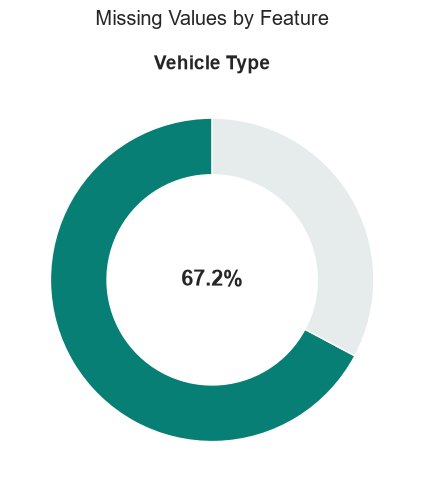

In [9]:
missing_percent = df.isna().mean() * 100
missing_percent = missing_percent[missing_percent > 0]

fig, axes = plt.subplots(
    1, len(missing_percent),
    figsize=(5 * len(missing_percent), 5)
)

if len(missing_percent) == 1:
    axes = [axes]

for ax, (column, percent) in zip(axes, missing_percent.items()):
    ax.pie(
        [percent, 100 - percent],
        colors=[MAIN_COLOR, "#E5ECEB"],
        startangle=90,
        wedgeprops={"width": 0.35, "edgecolor": "white"}
    )

    ax.set_title(column)
    ax.text(
        0, 0,
        f"{percent:.1f}%",
        ha="center",
        va="center",
        fontsize=16,
        fontweight="bold"
    )

plt.suptitle("Missing Values by Feature")
plt.tight_layout()
plt.show()

### 3.3 Missing values by transport
Check whether missing `Vehicle Type` values depend on `Transport`.

In [10]:
missing_by_transport = (
    df["Vehicle Type"]
    .isna()
    .groupby(df["Transport"])
    .mean() * 100
)

print("Percentage of missing Vehicle Type values by Transport:")
print(missing_by_transport.round(2))

Percentage of missing Vehicle Type values by Transport:
Transport
private           0.0
public          100.0
walk/bicycle    100.0
Name: Vehicle Type, dtype: float64


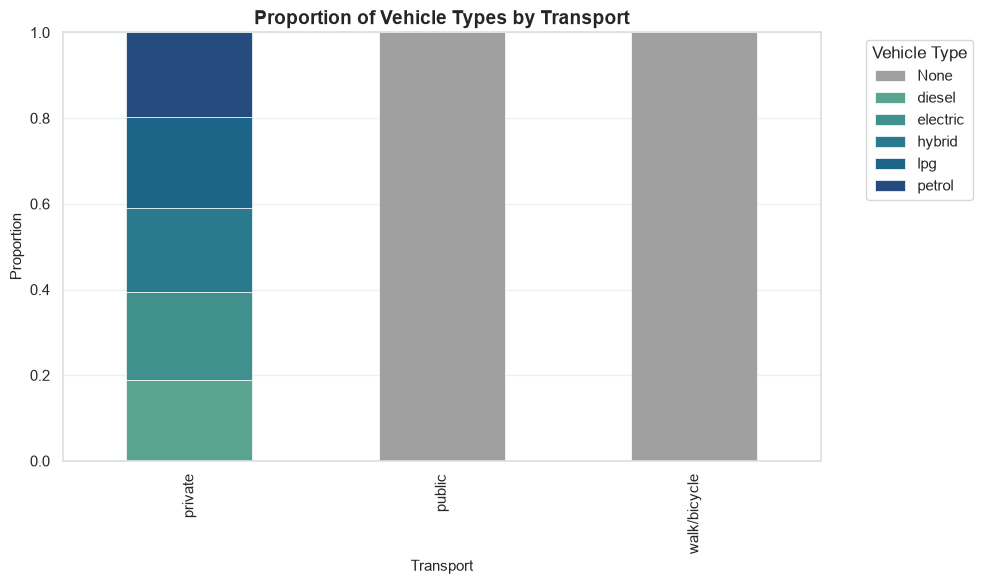

In [11]:
df_grouped = df[
    ["Vehicle Type", "Transport"]
].copy()

df_grouped = df_grouped.fillna("None")

df_crosstab = pd.crosstab(
    df_grouped["Transport"],
    df_grouped["Vehicle Type"],
    normalize="index"
)

category_palette = dict(zip(
    df_crosstab.columns,
    sns.color_palette(
        "crest",
        n_colors=len(df_crosstab.columns)
    ).as_hex()
))

category_palette["None"] = "#A0A0A0"

df_crosstab.plot(
    kind="bar",
    stacked=True,
    color=[
        category_palette[col]
        for col in df_crosstab.columns
    ],
    edgecolor="white",
    linewidth=0.5
)

plt.title("Proportion of Vehicle Types by Transport")
plt.xlabel("Transport")
plt.ylabel("Proportion")
plt.legend(
    title="Vehicle Type",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

### 3.4 Outliers
IQR rule and boxplots, plus the effect of outliers on the correlation with the target.

In [12]:
num_cols = df.select_dtypes(include=np.number).columns

outlier_summary = []

for column in num_cols:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - IQR * 1.5
    upper_bound = Q3 + IQR  *1.5

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]
    
    outlier_summary.append({
        "Feature": column,
        "Outliers": len(outliers),
        "Percentage": len(outliers) / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.round(2)

,Feature,Outliers,Percentage
0,Monthly Grocery Bill,0,0.00
1,Vehicle Monthly Distance Km,1294,12.94
2,Waste Bag Weekly Count,0,0.00
3,How Long TV PC Daily Hour,0,0.00
4,How Many New Clothes Monthly,0,0.00
5,How Long Internet Daily Hour,0,0.00
6,CarbonEmission,346,3.46


In [13]:
num_outliers = df[["Vehicle Monthly Distance Km", "CarbonEmission"]].copy()

for column in num_outliers.columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - IQR * 1.5
    upper_bound = Q3 + IQR * 1.5

    num_outliers = num_outliers[
        (num_outliers[column] >= lower_bound) &
        (num_outliers[column] <= upper_bound)
    ]

print("Correlation with outliers:")
corr_with_outliers = df[["Vehicle Monthly Distance Km", "CarbonEmission"]].corr()
display(corr_with_outliers.round(2))

print("Correlation without outliers:")
corr_without_outliers = num_outliers.corr()
display(corr_without_outliers.round(2))

print("Before removing outliers:", len(df))
print("After removing outliers:", len(num_outliers))
print("Number of removed outliers:", len(df) - len(num_outliers))
print("Percentage of removed outliers:", round(
    (len(df) - len(num_outliers)) / len(df) * 100, 2
))

Correlation with outliers:


,Vehicle Monthly Distance Km,CarbonEmission
Vehicle Monthly Distance Km,1.00,0.59
CarbonEmission,0.59,1.00


Correlation without outliers:


,Vehicle Monthly Distance Km,CarbonEmission
Vehicle Monthly Distance Km,1.00,0.35
CarbonEmission,0.35,1.00


Before removing outliers: 10000
After removing outliers: 8664
Number of removed outliers: 1336
Percentage of removed outliers: 13.36


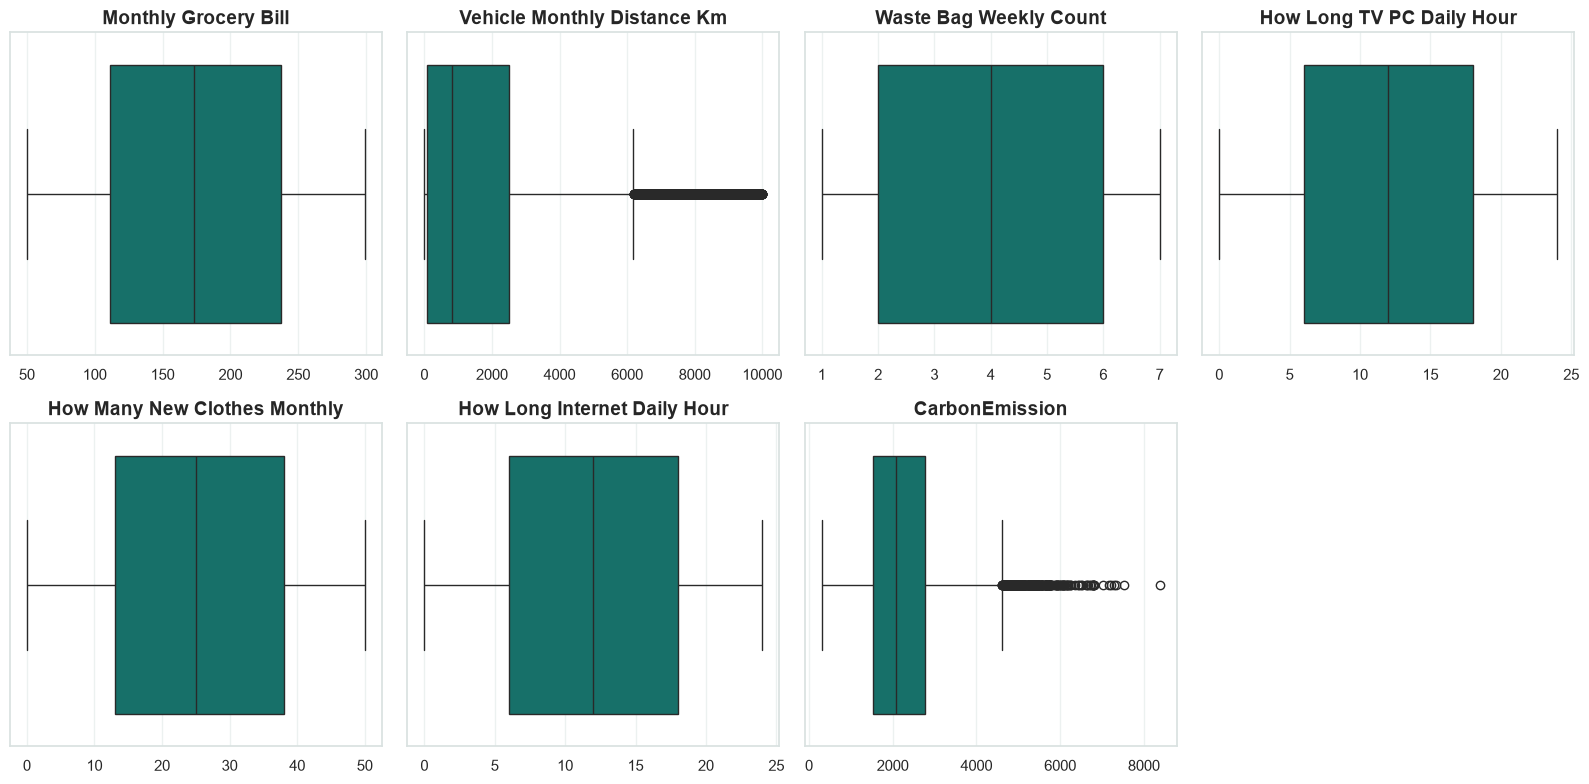

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, column in enumerate(num_cols):
    sns.boxplot(
        x=df[column],
        ax=axes[i],
        color=MAIN_COLOR
    )
    axes[i].set_title(column)
    axes[i].set_xlabel("")

for ax in axes[len(num_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

## 4. Exploratory data analysis
Distribution of the target and its relationships with selected features.

### 4.1 Carbon emission distribution
Shape and spread of `CarbonEmission`.

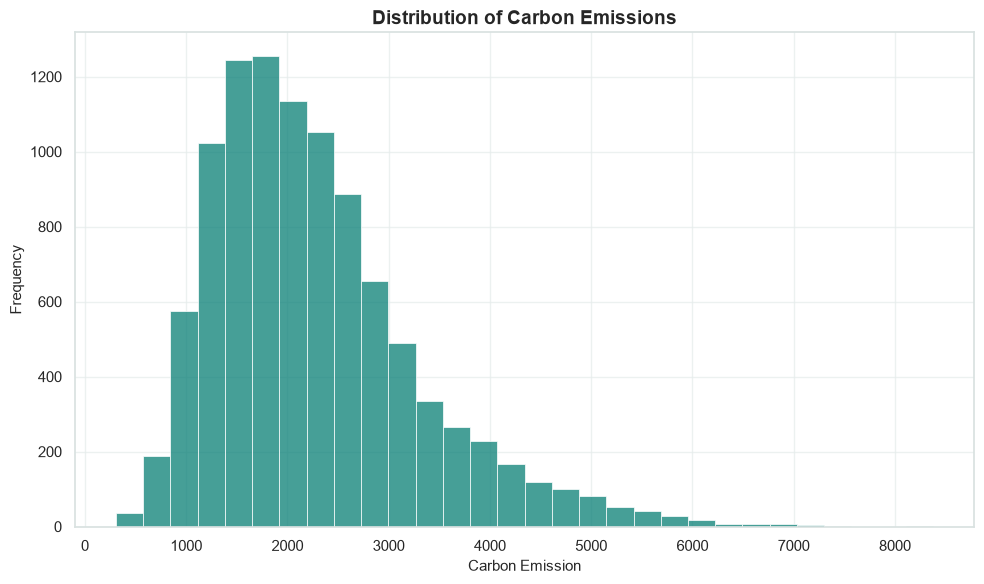

In [15]:
sns.histplot(
    df["CarbonEmission"],
    bins=30,
    color=MAIN_COLOR,
    edgecolor="white",
    linewidth=0.5
)
plt.title("Distribution of Carbon Emissions")
plt.xlabel("Carbon Emission")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### 4.2 Carbon emissions by diet
Emission distribution across diet categories.

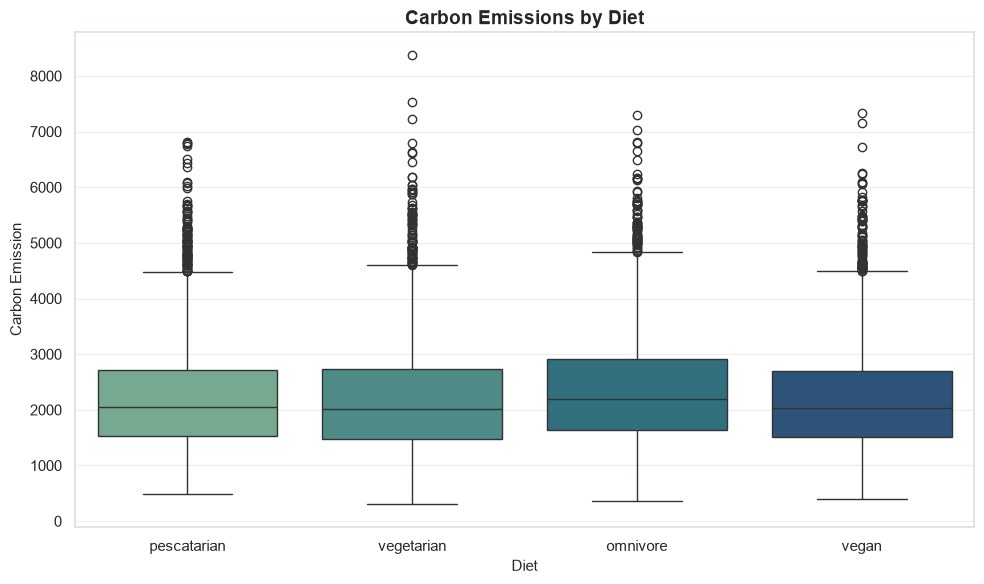

In [16]:
diet_palette = dict(zip(
    df["Diet"].dropna().unique(),
    sns.color_palette(
        "crest",
        n_colors=df["Diet"].nunique()
    ).as_hex()
))

sns.boxplot(
    x="Diet",
    y="CarbonEmission",
    data=df,
    hue="Diet",
    palette=diet_palette,
    legend=False
)

plt.title("Carbon Emissions by Diet")
plt.xlabel("Diet")
plt.ylabel("Carbon Emission")
plt.tight_layout()
plt.show()

### 4.3 Correlation of numerical features
Pearson correlation between numerical columns.

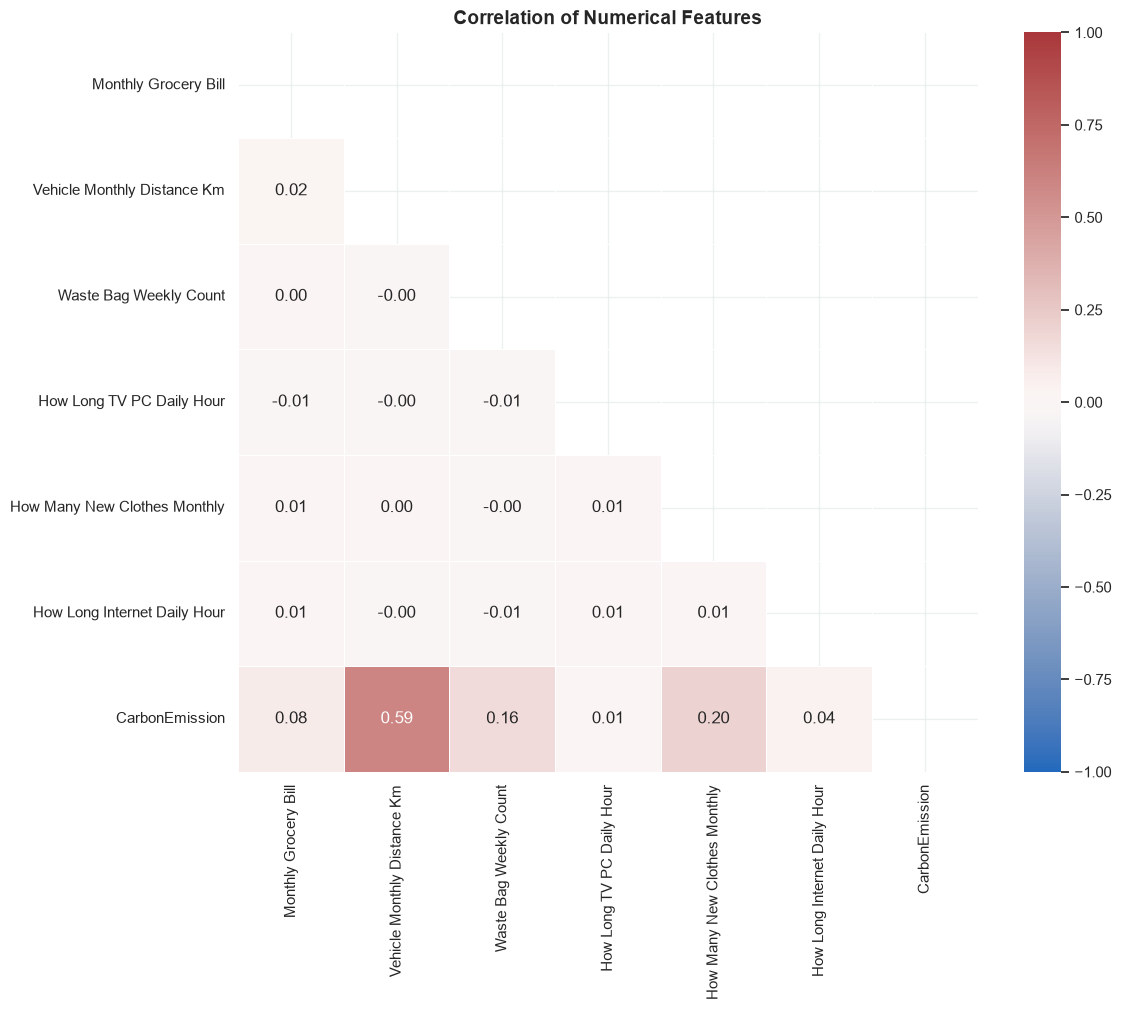

In [17]:
corr_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = df[corr_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Correlation of Numerical Features")
plt.tight_layout()
plt.show()

### 4.4 Carbon emissions by vehicle type
Mean, median and standard deviation of emissions per vehicle type.

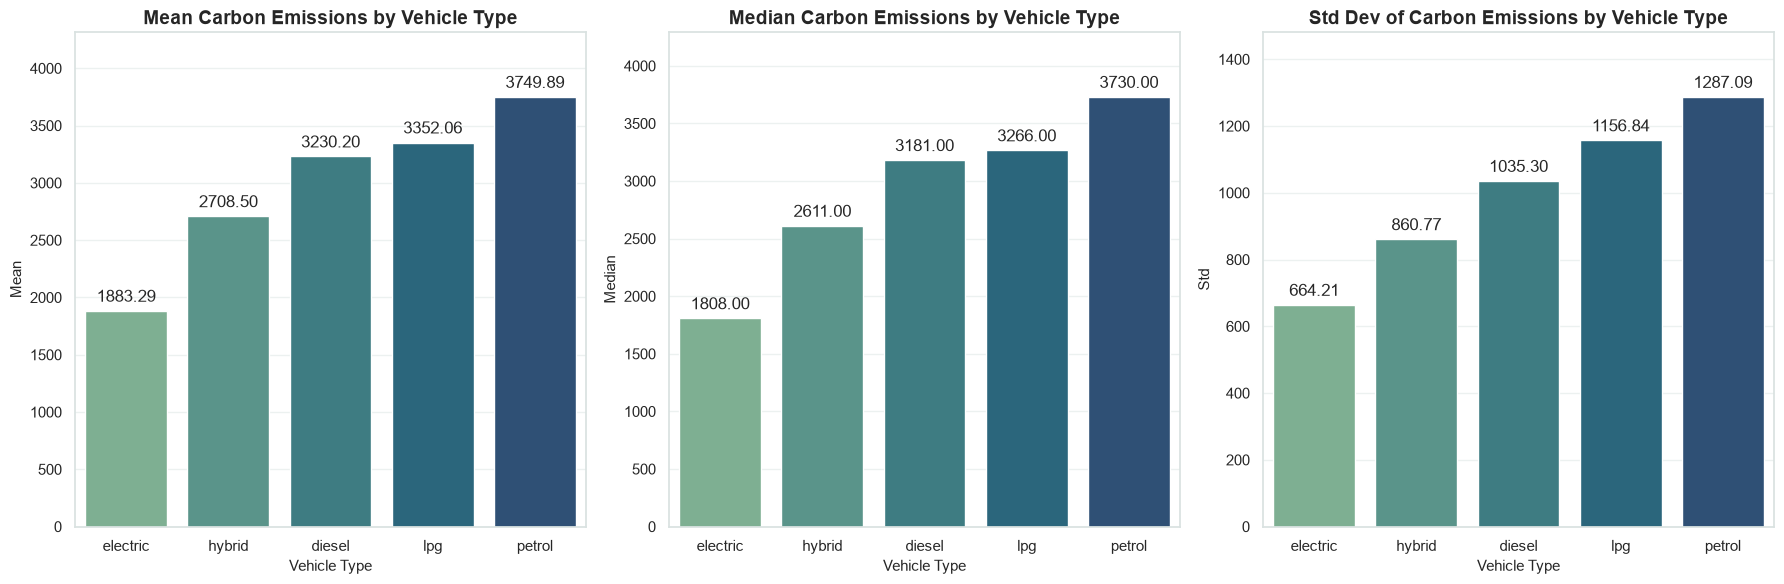

In [18]:
stats = (
    df.groupby("Vehicle Type")["CarbonEmission"]
    .agg(["mean", "median", "std"])
    .sort_values("mean")
    .round(2)
)

vehicle_palette = dict(zip(
    stats.index,
    sns.color_palette("crest", n_colors=len(stats)).as_hex()
))

metrics = ["mean", "median", "std"]
titles = ["Mean Carbon Emissions", "Median Carbon Emissions", "Std Dev of Carbon Emissions"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, metric, title in zip(axes, metrics, titles):
    sns.barplot(
        x=stats.index,
        y=stats[metric],
        hue=stats.index,
        palette=vehicle_palette,
        legend=False,
        ax=ax
    )
    
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=4)
        
    ax.margins(y=0.15)
    ax.set_title(f"{title} by Vehicle Type")
    ax.set_xlabel("Vehicle Type")
    ax.set_ylabel(metric.capitalize())

plt.tight_layout()
plt.show()

### 4.5 Vehicle monthly distance vs carbon emission
Scatter plot with a trend line, plus Pearson and Spearman correlation.

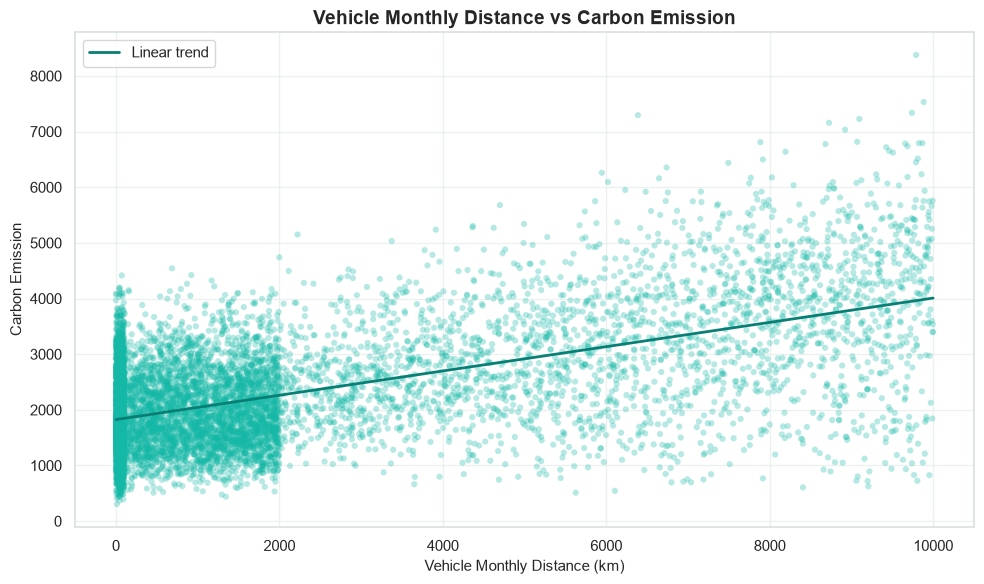

In [19]:
x = df["Vehicle Monthly Distance Km"]
y = df["CarbonEmission"]

slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(10, 6))

plt.scatter(
    x, y,
    alpha=0.3,
    s=20,
    color=SECONDARY_COLOR,
    edgecolors="none"
)

plt.plot(
    x.sort_values(),
    slope * x.sort_values() + intercept,
    color=MAIN_COLOR,
    linewidth=2,
    label="Linear trend"
)

plt.title("Vehicle Monthly Distance vs Carbon Emission")
plt.xlabel("Vehicle Monthly Distance (km)")
plt.ylabel("Carbon Emission")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
print("Pearson:", round(x.corr(y, method="pearson"), 3))
print("Spearman:", round(x.corr(y, method="spearman"), 3))

Pearson: 0.594
Spearman: 0.413


## 5. Conclusions

### Key findings
- The dataset has 10,000 observations and 20 features, with no duplicate rows.
- Missing values occur only in `Vehicle Type` (67.21%). They appear for every `public` and `walk/bicycle` user and never for `private`, so they mean "no private vehicle".
- Monthly vehicle distance is positively correlated with emissions (Pearson 0.59, Spearman 0.41).
- `Vehicle Monthly Distance Km` has 12.94% outliers and `CarbonEmission` 3.46%. Removing them lowers the correlation from 0.59 to 0.35, so they carry real signal.
- `CarbonEmission` is right-skewed: most values are between about 1,000 and 3,500, with a long tail up to about 8,000.
- Diet has only a small effect. Omnivores have a slightly higher median (around 2,200) than the other diets (around 2,000), but the distributions overlap almost completely. Outliers appear in every diet.

### Decisions
- Missing `Vehicle Type` values are kept as their own category (`None`).
- No duplicates, so nothing is removed.
- Outliers are kept because they are real observations. `RobustScaler` limits their effect on scaling.

### Preprocessing plan
- Numerical features: median imputation and `RobustScaler`.
- Text features: constant imputation and one-hot encoding.
- List columns (`Recycling`, `Cooking_With`): `MultiLabelBinarizer`.
- Preprocessing is fitted only on training data, inside the model pipelines.